# Who invests in the world's farms?

The working behind the [findings report](../findings/README.md): foreign direct investment in agriculture, forestry and fishing, using World Bank open data.

The calculations live in [`findings/analysis.py`](../findings/analysis.py) and the charts in [`findings/charts.py`](../findings/charts.py), so this notebook, the report and the tests all share the same code.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / "findings").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "findings"))

import analysis as an
import charts

## 1. Know the data before adding it up

The raw file has 37 columns, but only a few vary. The important one is `UNIT_MEASURE`: the file holds most country-years **twice**, once in current dollars and once at constant 2015 prices.

In [2]:
raw = pd.read_csv(an.RAW)
print(f"{raw.shape[0]:,} rows, {raw.shape[1]} columns")
raw.groupby("UNIT_MEASURE_LABEL").agg(rows=("OBS_VALUE", "size"), countries=("REF_AREA", "nunique"))

3,320 rows, 37 columns


,rows,countries
UNIT_MEASURE_LABEL,,
US dollars,1669,109
"US dollars, 2015 constant prices",1651,108


Adding that column without filtering counts everything twice. The first version of this project did exactly that:

In [3]:
old = an.first_version()
pd.Series({
    "First version, all rows ($m)": round(old["old_total"]),
    "Correct, 2015 prices ($m)": round(old["correct_total"]),
    "First version's France model, R²": round(old["france_r2"], 2),
})

First version, all rows ($m)        305743.00
Correct, 2015 prices ($m)           158257.00
First version's France model, R²        -0.14
dtype: float64

From here on, all money is at constant 2015 prices. Taiwan only has current-dollar figures, so it drops out, leaving 108 countries.

Negative values are real: they mean more money left a country than arrived that year.

In [4]:
df = an.load()
print(f"{df['iso3'].nunique()} countries, {df['year'].min()} to {df['year'].max()}")
df.head()

108 countries, 2000 to 2023


,iso3,country,continent,year,fdi_usd_m_current,fdi_usd_m_2015
0,ALB,Albania,Europe,2004,0.642888,0.683942
1,ALB,Albania,Europe,2005,0.494601,0.494923
2,ALB,Albania,Europe,2006,2.508966,2.406540
3,ALB,Albania,Europe,2007,2.737334,2.318459
4,ALB,Albania,Europe,2008,-79.100597,-59.698190


## 2. Who reports changes every year

Only 30 countries report 2023, so summing every country would make the last years look like a collapse. To compare like with like, the trend uses only countries with a figure for every year from 2005 to 2021.

In [5]:
an.coverage(df).tail(6).to_frame("countries reporting").T

year,2018,2019,2020,2021,2022,2023
countries reporting,74,70,71,73,61,30


In [6]:
print(f"{len(an.panel_countries(df))} comparable countries")
an.panel_share_of_reported(df).round(2).to_frame("share of reported money").T

41 comparable countries


year,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
share of reported money,0.99,0.72,0.97,0.89,0.73,0.78,0.83,0.87,0.86,0.98,0.89,0.78,0.84,0.95,0.75,0.85,0.82


## 3. Investment surged, then fell back

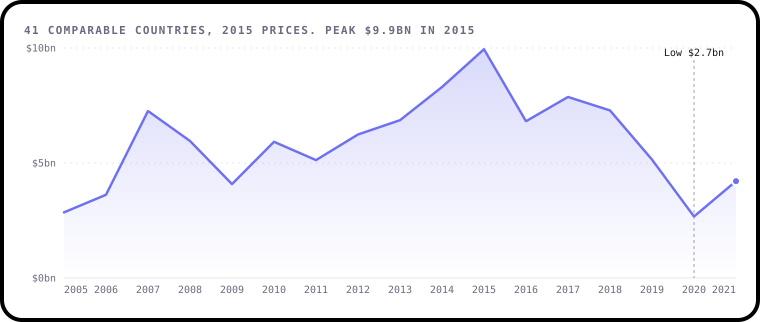

In [7]:
charts.comparable_trend(df)

## 4. One country explains most of the fall

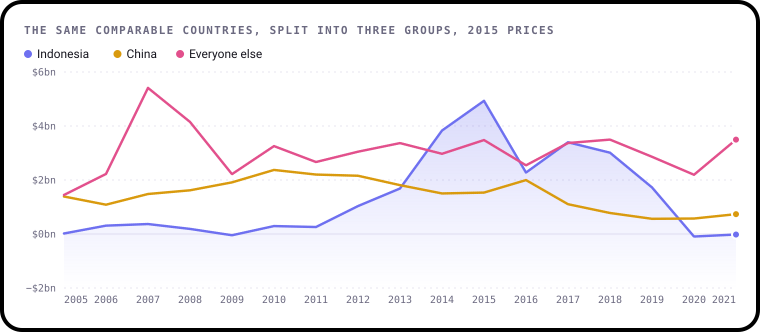

In [8]:
charts.who_drove_it(df)

In [9]:
an.share_of_fall(df).round(2).to_frame("share of the 2015 to 2020 fall")

,share of the 2015 to 2020 fall
Indonesia,0.69
China,0.13
Everyone else,0.18


## 5. One number looks like a global boom

Germany in 2012 is about two-thirds of that year's total. The data doesn't explain it, so it stays visible here but is left out of the rankings below.

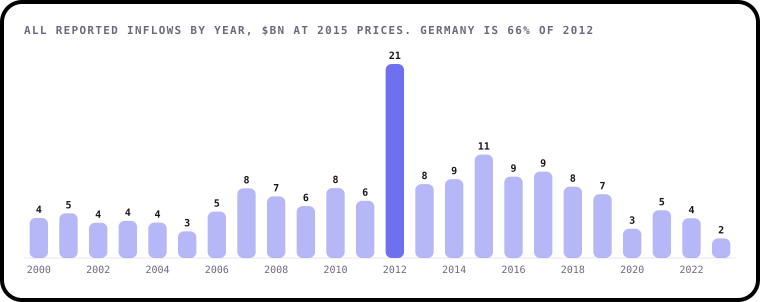

In [10]:
charts.one_figure(df)

In [11]:
pd.Series(an.one_figure(df)).round(2)

value                13814.30
share_of_year            0.66
other_years_net        194.09
other_years_count       20.00
other_years_max         75.61
dtype: float64

## 6. A few countries take most of the money

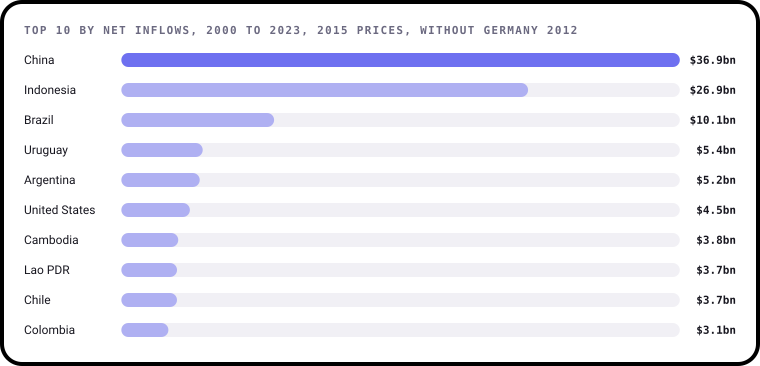

In [12]:
charts.top_countries(df)

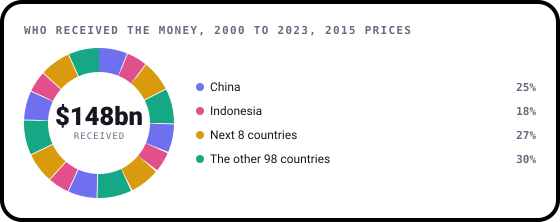

In [13]:
charts.concentration(df)

In [14]:
pd.Series(an.concentration(an.lifetime_totals(df))).round(3)

top_2            0.432
top_3            0.500
top_10           0.699
bottom_half      0.027
countries      108.000
dtype: float64

## 7. Geography, with a caveat

Only 18 African countries appear, so this is a picture of who reports as well as who receives.

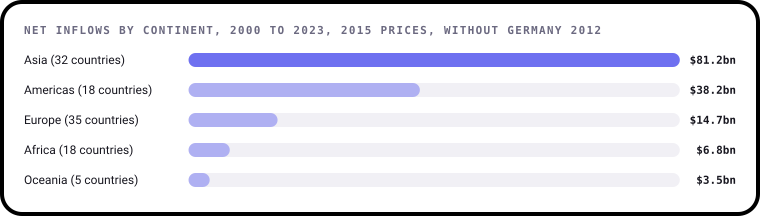

In [15]:
charts.continents(df)

## 8. Money leaves as well as arrives

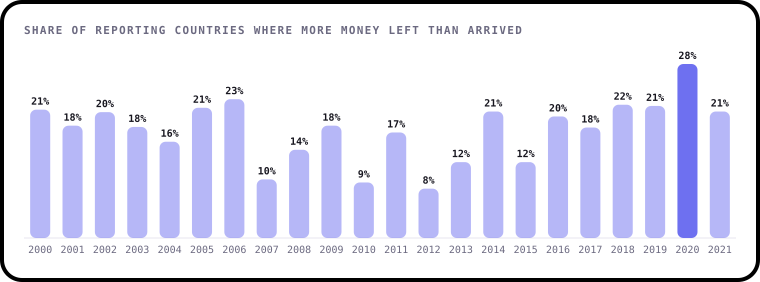

In [16]:
charts.outflows(df)

## 9. Can past values forecast this?

A fair test only lets a model see the past. For each year from 2012 to 2021, both methods get the years before it and nothing else. The first version's random split let its model train on years later than the ones it was tested on.

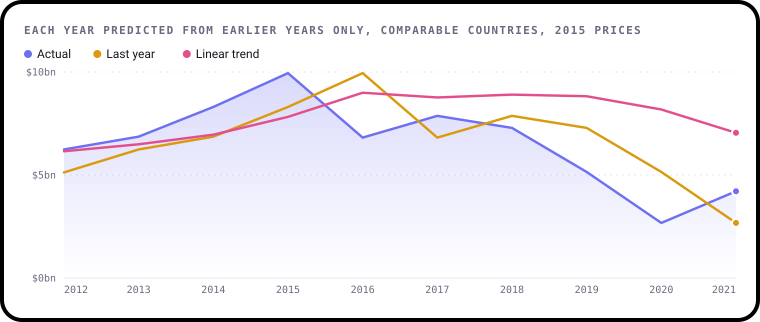

In [17]:
table = an.backtest(an.panel(df).sum(axis=1))
charts.forecast(df)

In [18]:
an.backtest_errors(table).round(0).to_frame("mean absolute error ($m)")

,mean absolute error ($m)
Last year,1574.0
Linear trend,2064.0


The straight line loses to simply repeating last year's figure. With ten test years that's a warning rather than a verdict, but past values alone clearly aren't enough here.

## Limits

- Not truly global: many countries report only some years.
- It shows what happened, not why. Nothing here explains Indonesia's fall or Germany's spike.
- These are reported figures, and methods vary between countries.